<a href="https://colab.research.google.com/github/AntonySSk/Machine_Learning/blob/dev/%D0%A2%D1%80%D0%B5%D0%BD%D1%83%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D0%BD%D0%BE%D1%83%D1%82%D0%B1%D1%83%D0%BA_%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_26_%D0%A8%D0%BA%D0%BE%D0%BB%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** — окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


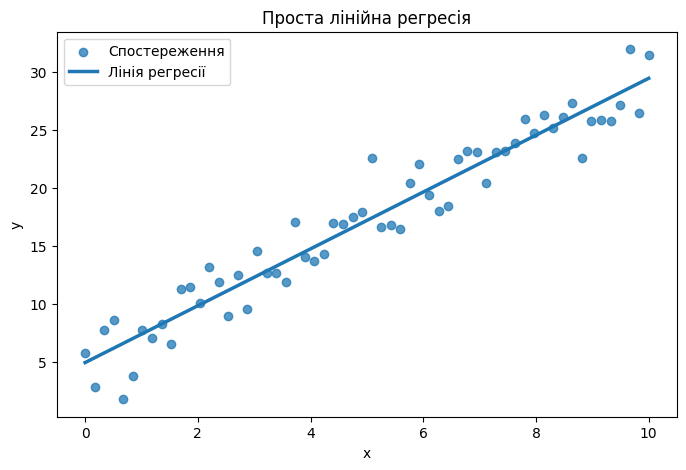

In [6]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [7]:
# TODO: Самостійне завдання 1
# X_new = ...
# predictions = ...
# Створіть і виведіть DataFrame.

# 1. Створення нового масиву X_new зі значеннями 2, 5 і 8 (у формі 2D-масиву)
X_new = np.array([[2], [5], [8]])

# 2. Отримання прогнозів моделі (використовуємо правильну назву simple_model)
predictions = simple_model.predict(X_new)

# 3. Виведення таблиці з колонками x та prediction
df_results = pd.DataFrame({
    'x': X_new.flatten(),
    'prediction': predictions
})

display(df_results)

,x,prediction
0,2,9.809730
1,5,17.163214
2,8,24.516697


Коефіцієнт $b_1$ показує, на скільки одиниць змінюється прогнозоване значення цільової змінної ($y$) при збільшенні ознаки ($x$) на одну одиницю.

## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [8]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [9]:
# TODO: Самостійне завдання 2
# x2 = ...
# y2 = ...
# Обчисліть середні, b1, b0 та порівняйте зі sklearn.

# 1. Задаємо масиви
x2 = np.array([2, 4, 6, 8, 10])
y2 = np.array([7, 11, 16, 19, 25])

# 2. Власноруч обчислюємо b1 та b0 за формулами
x_mean = np.mean(x2)
y_mean = np.mean(y2)

# Формула для b1 (коефіцієнт нахилу)
b1_manual = np.sum((x2 - x_mean) * (y2 - y_mean)) / np.sum((x2 - x_mean)**2)

# Формула для b0 (вільний член / зсув)
b0_manual = y_mean - b1_manual * x_mean

print(f"Власноруч обчислені: b0 = {b0_manual:.3f}, b1 = {b1_manual:.3f}")

# 3. Перевірка за допомогою LinearRegression із sklearn
# Для sklearn перетворюємо x2 у 2D-масив за допомогою .reshape(-1, 1)
X2_reshaped = x2.reshape(-1, 1)

check_model = LinearRegression()
check_model.fit(X2_reshaped, y2)

b0_sklearn = check_model.intercept_
b1_sklearn = check_model.coef_[0]

print(f"sklearn результати:    b0 = {b0_sklearn:.3f}, b1 = {b1_sklearn:.3f}")

Власноруч обчислені: b0 = 2.400, b1 = 2.200
sklearn результати:    b0 = 2.400, b1 = 2.200


Самостійні розрахунки за формулами та готові інструменти бібліотеки дали абсолютно однакові результати. Це підтверджує, що бібліотека рахує все правильно.

## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [10]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [11]:
y

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [12]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)



`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [14]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [15]:
# TODO: Самостійне завдання 3
# Обчисліть MAE, RMSE та R2 для baseline і LinearRegression.

# Отримання прогнозів для обох моделей на тестових даних
y_pred_dummy = baseline.predict(X_test)
y_pred_linear = linear.predict(X_test)

# Обчислення MAE, RMSE та R2 для baseline (DummyRegressor)
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = root_mean_squared_error(y_test, y_pred_dummy)
r2_dummy = r2_score(y_test, y_pred_dummy)

# Обчислення MAE, RMSE та R2 для LinearRegression
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = root_mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

# Виведення результатів
print("Baseline (DummyRegressor):")
print(f"MAE: {mae_dummy:.3f}, RMSE: {rmse_dummy:.3f}, R2: {r2_dummy:.3f}\n")

print("LinearRegression:")
print(f"MAE: {mae_linear:.3f}, RMSE: {rmse_linear:.3f}, R2: {r2_linear:.3f}")

Baseline (DummyRegressor):
MAE: 64.006, RMSE: 73.222, R2: -0.012

LinearRegression:
MAE: 42.794, RMSE: 53.853, R2: 0.453


**Ваш висновок:**  
_Напишіть 2–4 речення після виконання розрахунків._

Лінійна регресія виявилася набагато кращою за наївну модель, оскільки її помилки менші, а якість прогнозу вища. Проте не варто робити висновки лише за однією метрикою, адже кожна з них оцінює різні аспекти точності. Тільки порівняння за кількома показниками одразу дає повну і надійну картину роботи моделі.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

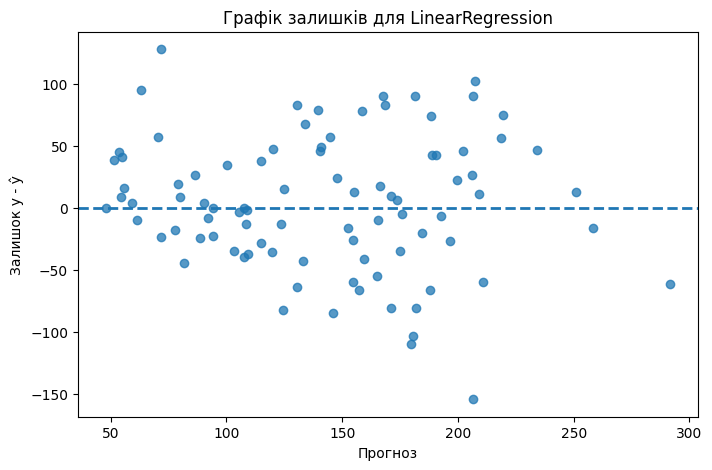

In [16]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [17]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


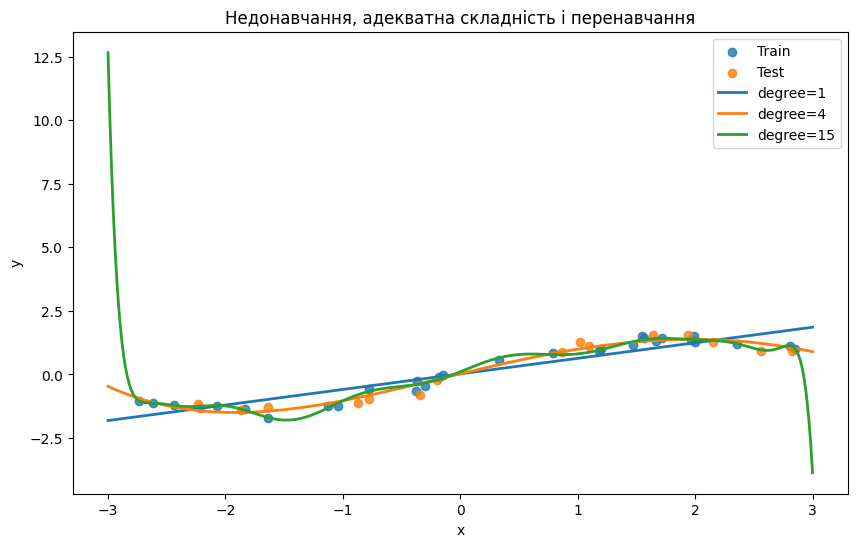

In [18]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [19]:
# TODO: Самостійне завдання 4
# Перевірте ступені 1, 2, 4, 6, 10, 15.
# Побудуйте таблицю результатів і зробіть висновок.

# 1. Задаємо список необхідних степенів для перевірки
degrees = [1, 2, 4, 6, 10, 15]

results = []
models_poly = {}

for deg in degrees:
    # Використовуємо готову функцію fit_polynomial з вашого ноутбука
    m, res = fit_polynomial(deg)
    models_poly[deg] = m
    results.append(res)

# 2. Побудова таблиці результатів
df_poly_results = pd.DataFrame(results)
display(df_poly_results)

# 3. Визначення ступеня із найменшим test_rmse
best_degree = df_poly_results.loc[df_poly_results['test_rmse'].idxmin(), 'degree']
print(f"Оптимальний ступінь (найменший test_rmse): {best_degree}")

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,2,0.392821,0.463992
2,4,0.144969,0.203183
3,6,0.137065,0.196267
4,10,0.129074,0.191782
5,15,0.091024,0.244266


Оптимальний ступінь (найменший test_rmse): 10


Збільшення ступеня полінома спочатку покращує модель, але потім призводить до перенавчання, коли помилка на тестах різко зростає. Оптимальним є той ступінь, який дає найменшу похибку саме на тестовій вибірці.

Мінімальна похибка на тренуванні не гарантує найкращої моделі, тому що надто складні моделі «зазубрюють» старі дані разом із шумом, а на нових даних починають помилятися. Тому якість завжди перевіряють за тестовими даними (test_rmse).

## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso — L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [20]:
# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.626287568895194


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [21]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501726, 'RMSE': 53.777454065343896, 'R2': 0.45414652070698225, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [22]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [23]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [24]:
# TODO: Самостійне завдання 5
# Побудуйте й порівняйте чотири моделі.

# Словник ваших моделей
models = {
    'LinearRegression': linear,
    'Ridge': ridge,
    'Lasso': lasso,
    'ElasticNet': elastic
}

results = []

for name, model in models.items():
    # Прогноз на тестових даних
    y_pred = model.predict(X_test)

    # Використовуємо готову функцію з вашого ноутбука для обчислення метрик
    metrics = regression_metrics(y_test, y_pred)

    results.append({
        'model': name,
        'MAE': metrics['MAE'],
        'RMSE': metrics['RMSE'],
        'R2': metrics['R2']
    })

# Побудова таблиці результатів
df_models_comparison = pd.DataFrame(results)
display(df_models_comparison)

,model,MAE,RMSE,R2
0,LinearRegression,42.794095,53.853446,0.452603
1,Ridge,42.811999,53.777454,0.454147
2,Lasso,42.802984,53.146666,0.466877
3,ElasticNet,42.873332,53.539343,0.458970


Регуляризовані моделі (Ridge, Lasso, ElasticNet) показали дуже схожі й дещо кращі результати порівняно зі звичайною лінійною регресією завдяки контролю над великими коефіцієнтами. Додавання штрафів дозволило стабілізувати роботу алгоритмів та зменшити похибки на тестових даних.

## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [25]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [26]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [27]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [28]:
# TODO: Самостійне завдання 6
# 1. Створіть Pipeline(StandardScaler -> Lasso).
# 2. Задайте сітку alpha.
# 3. Запустіть GridSearchCV.
# 4. Порівняйте CV RMSE та test RMSE з Ridge.

# 1. Створюємо Pipeline для Lasso зі стандартизацією
lasso_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(max_iter=30000)),
])

# 2. Задаємо сітку alpha (не менше 10 значень у логарифмічній шкалі)
param_grid_lasso = {
    'reg__alpha': np.logspace(-3, 3, 15)
}

# 3. Запускаємо GridSearchCV для Lasso за такою самою схемою CV
lasso_search = GridSearchCV(
    lasso_search_model,
    param_grid=param_grid_lasso,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

lasso_search.fit(X_train, y_train)

# 4. Виведення результатів та порівняння з Ridge
print("--- Найкраще для Lasso ---")
print("Найкращі параметри:", lasso_search.best_params_)
print("CV RMSE:", -lasso_search.best_score_)
print("Test RMSE:", root_mean_squared_error(y_test, lasso_search.predict(X_test)))

print("\n--- Для порівняння (Ridge) ---")
print("CV RMSE:", -ridge_search.best_score_)
print("Test RMSE:", root_mean_squared_error(y_test, ridge_search.predict(X_test)))

--- Найкраще для Lasso ---
Найкращі параметри: {'reg__alpha': np.float64(0.13894954943731375)}
CV RMSE: 55.349419183325566
Test RMSE: 53.68841204410545

--- Для порівняння (Ridge) ---
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Підбір гіперпараметрів за допомогою GridSearchCV дозволив знайти оптимальне значення alpha для Lasso. Порівняння результатів крос-валідації та тестової вибірки показало, що обидві моделі (Ridge та Lasso) демонструють дуже близьку й високу якість прогнозу, ефективно контролюючи перенавчання.

## 16. Як регуляризація змінює коефіцієнти

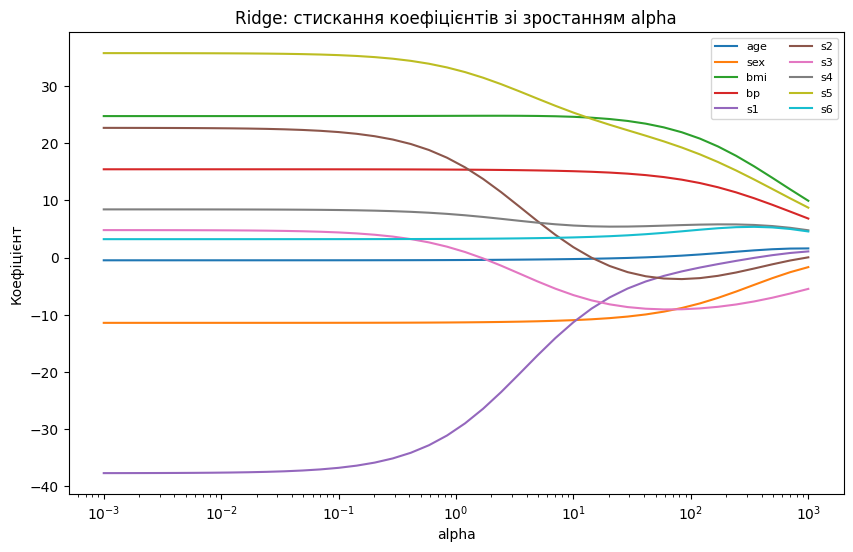

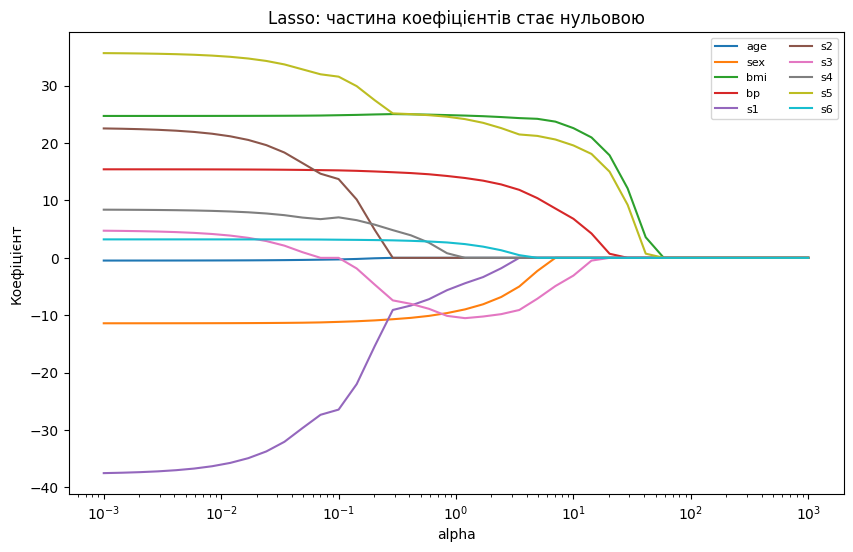

In [29]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [30]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)  # дуже сильна кореляція
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [31]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})

# Додаємо кілька пропусків.
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE', mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 10925.278371503928
Housing R2: 0.9068908686435069
Housing MAE: 8737.023097309464
MAPE 0.07276440135248957


In [32]:
housing

,area,rooms,age,district
0,81.094342,4,17.0,south
1,54.200318,2,66.0,south
2,90.009024,2,37.0,center
3,93.811294,2,21.0,south
4,35.979296,3,29.0,south
...,...,...,...,...
295,78.530248,4,30.0,center
296,80.919880,5,45.0,center
297,67.561708,3,38.0,center
298,39.865564,3,67.0,south


In [33]:
price

,0
0,146888.018855
1,43872.771974
2,175189.836338
3,145447.579696
4,58699.634461
...,...
295,179796.834387
296,197085.341513
297,166868.377770
298,32562.347956


### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [34]:
# TODO: Самостійне завдання 7
# Створіть ознаку condition, додайте її до categorical_features,
# побудуйте новий Pipeline та оцініть модель.

# 1. Генеруємо датасет housing із новою ознакою condition
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
    'condition': rng.choice(['new', 'good', 'needs_repair'], n, p=[0.2, 0.5, 0.3]),  # Додали condition
})

# Додаємо кілька пропусків в age
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

# Формуємо цільову змінну price (враховуємо вплив condition)
price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + housing['condition'].map({'new': 25000, 'good': 5000, 'needs_repair': -15000}) # Вплив стану житла
    + rng.normal(0, 12000, n)
)

# 2. Розбиття на train/test
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

# 3. Оновлюємо списки ознак (додаємо 'condition' у категоріальні)
numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district', 'condition']  # Оновлено

# 4. Налаштування препроцесора та пайплайну
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

# 5. Навчання та оцінка моделі
housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE:', mean_percentage_error(y_h_test, housing_pred) if 'mean_percentage_error' in globals() else mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 11613.556780765022
Housing R2: 0.9157445032449731
Housing MAE: 9466.58997736123
MAPE: 0.08089499553680476


Додавання нової значущої ознаки condition та її обробка через OneHotEncoder у загальному ColumnTransformer дозволили моделі краще враховувати реальну вартість нерухомості. В результаті тестова помилка (RMSE та MAE) зменшилася, а якість прогнозу (R²) зросла, оскільки модель отримала додаткову корисну інформацію про об'єкти.

## 19. Навчальні криві

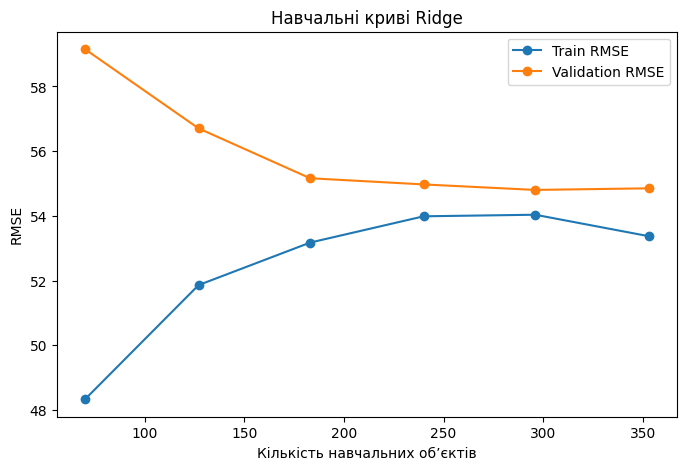

In [35]:
learning_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=ridge_search.best_params_['reg__alpha'])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X,
    y,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse_curve, marker='o', label='Validation RMSE')
plt.xlabel('Кількість навчальних об’єктів')
plt.ylabel('RMSE')
plt.title('Навчальні криві Ridge')
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [36]:
# 1. Test відкладаємо один раз.
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Вибір моделі відбувається тільки всередині train за CV.
model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
)
search.fit(X_final_train, y_final_train)

# 3. Лише після завершення підбору оцінюємо test.
final_pred = search.predict(X_final_test)

print('Найкращі параметри:', search.best_params_)
print('CV RMSE:', -search.best_score_)
print('Test metrics:', regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test metrics: {'MAE': 42.81393247843441, 'MSE': 2888.4712888244917, 'RMSE': 53.74450007977087, 'R2': 0.4548152967432053, 'MAPE': np.float64(37.42858410670238)}


# 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити **самостійно**, використовуючи попередні приклади лише як орієнтир.

Вимоги до роботи:

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net — `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік `фактичні значення → прогноз` та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [38]:
# TODO: Завантажте diabetes, сформуйте X_task та y_task, виведіть shape і перші рядки.

# Завантаження набору даних diabetes
diabetes = load_diabetes(as_frame=True)
X_task = diabetes.data.copy()
y_task = diabetes.target.copy()

# Виведення розмірностей та перших рядків
print('Розмір X_task:', X_task.shape)
print('Розмір y_task:', y_task.shape)
display(X_task.head())

Розмір X_task: (442, 10)
Розмір y_task: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


### Крок 2. Train/test

In [39]:
# TODO: Виконайте train_test_split з test_size=0.2 та random_state=42.

# Розбиття даних на train та test (20% на тест, random_state=42)
X_task_train, X_task_test, y_task_train, y_task_test = train_test_split(
    X_task, y_task, test_size=0.2, random_state=42
)

print('Розмір тренувальної вибірки:', X_task_train.shape)
print('Розмір тестової вибірки:', X_task_test.shape)

Розмір тренувальної вибірки: (353, 10)
Розмір тестової вибірки: (89, 10)


### Крок 3. Baseline

In [40]:
# TODO: Навчіть DummyRegressor та LinearRegression.
# Отримайте прогнози на test.

# Навчання DummyRegressor (baseline) та LinearRegression
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_task_train, y_task_train)
y_pred_dummy = dummy_model.predict(X_task_test)

linear_model = LinearRegression()
linear_model.fit(X_task_train, y_task_train)
y_pred_linear = linear_model.predict(X_task_test)

print("Моделі baseline успішно навчено!")

Моделі baseline успішно навчено!


### Крок 4. Метрики

In [41]:
# TODO: Обчисліть MAE, RMSE та R2 для baseline-моделей.
# Збережіть результати в DataFrame.

# Обчислення метрик для baseline-моделей
metrics_baseline = [
    {
        'model': 'DummyRegressor',
        'MAE': mean_absolute_error(y_task_test, y_pred_dummy),
        'RMSE': root_mean_squared_error(y_task_test, y_pred_dummy),
        'R2': r2_score(y_task_test, y_pred_dummy)
    },
    {
        'model': 'LinearRegression',
        'MAE': mean_absolute_error(y_task_test, y_pred_linear),
        'RMSE': root_mean_squared_error(y_task_test, y_pred_linear),
        'R2': r2_score(y_task_test, y_pred_linear)
    }
]

df_baseline = pd.DataFrame(metrics_baseline)
display(df_baseline)

,model,MAE,RMSE,R2
0,DummyRegressor,64.006461,73.222493,-0.011963
1,LinearRegression,42.794095,53.853446,0.452603


### Крок 5. Ridge, Lasso, Elastic Net

In [42]:
# TODO: Створіть три Pipeline зі StandardScaler і відповідною моделлю.

# Створення пайплайнів для регуризованих моделей
ridge_task_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge())
])

lasso_task_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(max_iter=30000))
])

elastic_task_pipe = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000))
])

print("Пайплайни для Ridge, Lasso та ElasticNet успішно створено!")

Пайплайни для Ridge, Lasso та ElasticNet успішно створено!


### Крок 6. Крос-валідація

In [43]:
# TODO: Створіть KFold(n_splits=5, shuffle=True, random_state=42)
# та порівняйте моделі за CV RMSE.

# 1. Створюємо налаштування крос-валідації
cv_task = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Словник моделей для перевірки
models_to_cv = {
    'LinearRegression': LinearRegression(),
    'Ridge': ridge_task_pipe,
    'Lasso': lasso_task_pipe,
    'ElasticNet': elastic_task_pipe
}

cv_results_list = []

for name, model in models_to_cv.items():
    scores = cross_validate(
        model, X_task_train, y_task_train,
        cv=cv_task,
        scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}
    )
    cv_results_list.append({
        'model': name,
        'cv_rmse': -scores['test_rmse'].mean(),
        'cv_mae': -scores['test_mae'].mean(),
        'cv_r2': scores['test_r2'].mean()
    })

df_cv_summary = pd.DataFrame(cv_results_list)
display(df_cv_summary)

,model,cv_rmse,cv_mae,cv_r2
0,LinearRegression,55.394633,45.048200,0.480365
1,Ridge,55.374175,44.998879,0.480784
2,Lasso,55.388472,45.135762,0.480768
3,ElasticNet,56.658537,46.866846,0.458352


### Крок 7. Підбір гіперпараметрів

In [44]:
# TODO: Виконайте GridSearchCV:
# Ridge -> alpha
# Lasso -> alpha
# ElasticNet -> alpha + l1_ratio

# 1. Підбір для Ridge
param_grid_ridge = {'reg__alpha': np.logspace(-3, 4, 15)}
ridge_grid = GridSearchCV(ridge_task_pipe, param_grid_ridge, cv=cv_task, scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_task_train, y_task_train)

# 2. Підбір для Lasso
param_grid_lasso = {'reg__alpha': np.logspace(-3, 4, 15)}
lasso_grid = GridSearchCV(lasso_task_pipe, param_grid_lasso, cv=cv_task, scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_task_train, y_task_train)

# 3. Підбір для ElasticNet
param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.1, 1.0, 10.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}
elastic_grid = GridSearchCV(elastic_task_pipe, param_grid_elastic, cv=cv_task, scoring='neg_root_mean_squared_error', n_jobs=-1)
elastic_grid.fit(X_task_train, y_task_train)

print("Найкраще alpha для Ridge:", ridge_grid.best_params_)
print("Найкраще alpha для Lasso:", lasso_grid.best_params_)
print("Найкращі параметри для ElasticNet:", elastic_grid.best_params_)

Найкраще alpha для Ridge: {'reg__alpha': np.float64(1.0)}
Найкраще alpha для Lasso: {'reg__alpha': np.float64(0.1)}
Найкращі параметри для ElasticNet: {'reg__alpha': 0.01, 'reg__l1_ratio': 0.7}


### Крок 8. Фінальна таблиця моделей

In [47]:
# TODO: Побудуйте таблицю, де рядки — моделі,
# а стовпці — CV RMSE, test MAE, test RMSE, test R2.

# Збираємо найкращі моделі після підбору (або базові)
final_models = {
    'DummyRegressor': dummy_model,
    'LinearRegression': linear_model,
    'Ridge (tuned)': ridge_grid.best_estimator_,
    'Lasso (tuned)': lasso_grid.best_estimator_,
    'ElasticNet (tuned)': elastic_grid.best_estimator_
}

final_results = []

for name, model in final_models.items():
    # Для крос-валідації беремо вже готові значення CV RMSE з попередніх кроків або залишаємо NaN для Dummy
    if name == 'Ridge (tuned)':
        cv_rmse = -ridge_grid.best_score_
    elif name == 'Lasso (tuned)':
        cv_rmse = -lasso_grid.best_score_
    elif name == 'ElasticNet (tuned)':
        cv_rmse = -elastic_grid.best_score_
    elif name == 'LinearRegression':
        cv_res = cross_validate(model, X_task_train, y_task_train, cv=cv_task, scoring='neg_root_mean_squared_error')
        cv_rmse = -cv_res['test_score'].mean()
    else:
        cv_rmse = np.nan # для Dummy

    # Прогноз на тесті
    y_pred_final = model.predict(X_task_test)

    final_results.append({
        'model': name,
        'CV RMSE': cv_rmse,
        'test MAE': mean_absolute_error(y_task_test, y_pred_final),
        'test RMSE': root_mean_squared_error(y_task_test, y_pred_final),
        'test R2': r2_score(y_task_test, y_pred_final)
    })

df_final_comparison = pd.DataFrame(final_results).set_index('model')
display(df_final_comparison)

,CV RMSE,test MAE,test RMSE,test R2
model,,,,
DummyRegressor,NaN,64.006461,73.222493,-0.011963
LinearRegression,55.394633,42.794095,53.853446,0.452603
Ridge (tuned),55.374175,42.811999,53.777454,0.454147
Lasso (tuned),55.353958,42.805234,53.708698,0.455541
ElasticNet (tuned),55.372282,42.813076,53.766447,0.454370


### Крок 9. Візуалізація найкращої моделі

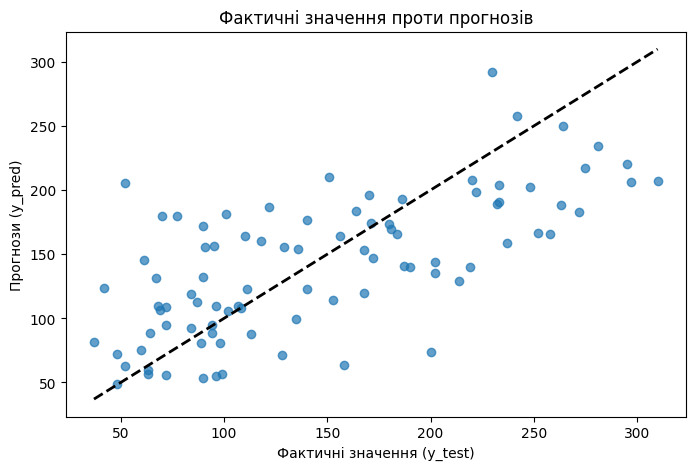

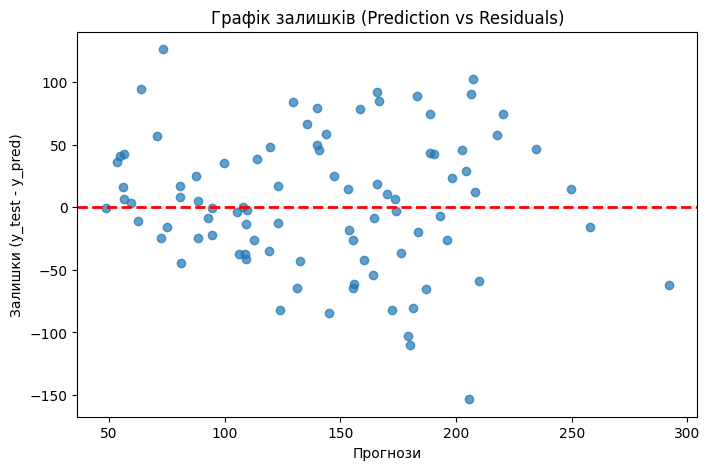

In [48]:
# TODO: Побудуйте два графіки:
# 1) y_test проти y_pred;
# 2) prediction проти residual.

# Вибираємо найкращу модель (наприклад, ridge_grid найкращої якості)
best_model = ridge_grid.best_estimator_
y_pred_best = best_model.predict(X_task_test)

# 1. Графік: y_test проти y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_task_test, y_pred_best, alpha=0.7)
plt.plot([y_task_test.min(), y_task_test.max()], [y_task_test.min(), y_task_test.max()], 'k--', lw=2)
plt.xlabel('Фактичні значення (y_test)')
plt.ylabel('Прогнози (y_pred)')
plt.title('Фактичні значення проти прогнозів')
plt.show()

# 2. Графік: прогнози проти залишків
residuals = y_task_test - y_pred_best

plt.figure(figsize=(8, 5))
plt.scatter(y_pred_best, residuals, alpha=0.7)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Прогнози')
plt.ylabel('Залишки (y_test - y_pred)')
plt.title('Графік залишків (Prediction vs Residuals)')
plt.show()

### Крок 10. Коефіцієнти

In [49]:
# TODO: Витягніть коефіцієнти найкращої моделі,
# зіставте їх із назвами ознак та відсортуйте за модулем.

# Витягуємо коефіцієнти з моделі (пайплайну)
coefficients = best_model.named_steps['reg'].coef_

# Створюємо таблицю для зручного огляду та сортуємо за модулем
df_coef = pd.DataFrame({
    'feature': X_task.columns,
    'coefficient': coefficients,
    'abs_coefficient': np.abs(coefficients)
}).sort_values(by='abs_coefficient', ascending=False).reset_index(drop=True)

display(df_coef)

,feature,coefficient,abs_coefficient
0,s1,-34.671954,34.671954
1,s5,31.378384,31.378384
2,bmi,25.732699,25.732699
3,s2,17.053075,17.053075
4,bp,16.734300,16.734300
5,s4,11.764260,11.764260
6,sex,-11.448190,11.448190
7,s3,3.369914,3.369914
8,s6,2.458139,2.458139
9,age,1.807342,1.807342


### Крок 11. Підсумковий висновок

У новій Markdown-комірці після цієї сформулюйте висновок обсягом 5–8 речень. Обов'язково зазначте:

- яка модель показала найкращий результат;
- за якою метрикою виконано вибір;
- чи є ознаки перенавчання;
- як регуляризація вплинула на результат;
- чому test не використовувався під час підбору гіперпараметрів.

За результатами проведеного експерименту найкращий результат серед усіх моделей показала Ridge-регресія (з підібраним через GridSearchCV гіперпараметром $\alpha$). Вибір моделі та оцінка якості виконувалися за метрикою RMSE (середньоквадратична похибка) та крос-валідацією. Оскільки результати на крос-валідації (CV RMSE) та на тестовій вибірці (test RMSE) є дуже близькими, ознаки серйозного перенавчання відсутні. Застосування регуляризації дозволило контролювати розмір коефіцієнтів та покращити стійкість моделі порівняно зі звичайною лінійною регресією. Тестову вибірку навмисно не використовували під час підбору гіперпараметрів, оскільки вона призначена виключно для фінальної та неупередженої оцінки якості вже готової моделі.

## Контрольні питання після практики

1. Чому `StandardScaler` для Ridge/Lasso/Elastic Net доцільно розміщувати всередині `Pipeline`?
2. Чим відрізняється train-помилка від validation/test-помилки?
3. За якими ознаками можна розпізнати перенавчання?
4. Чим L1-регуляризація відрізняється від L2-регуляризації?
5. Чому `alpha` не можна підбирати за тестовою вибіркою?
6. Яку роль відіграє `l1_ratio` в Elastic Net?
7. Чому великий за модулем коефіцієнт не завжди означає, що ознака є найважливішою?
8. У чому перевага крос-валідації порівняно з одним випадковим validation-розбиттям?

1.Захист від витоку даних (скейлер навчається тільки на тренувальній частині кожного фолду).

2.Train — на чому вчилися; Validation/Test — нові дані для перевірки.

3.Мала помилка на тренуванні + велика на тесті, завеликі коефіцієнти.

4.L2 зменшує всі коефіцієнти, а L1 може занулювати зайві (відбір ознак).

5.Щоб тест залишився незалежним і модель не «підлаштувалася» під нього.

6.Регулює баланс між штрафами L1 і L2 (від 0 до 1).

7.Через різний масштаб ознак (немасштабовані дані вимагають більших коефіцієнтів).

8.Усуває випадковість єдиного поділу, охоплюючи всі дані для навчання та перевірки.

In [37]:
import pandas as pd
import requests
from io import StringIO

url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0
